CSV exists: True
PDF exists: True


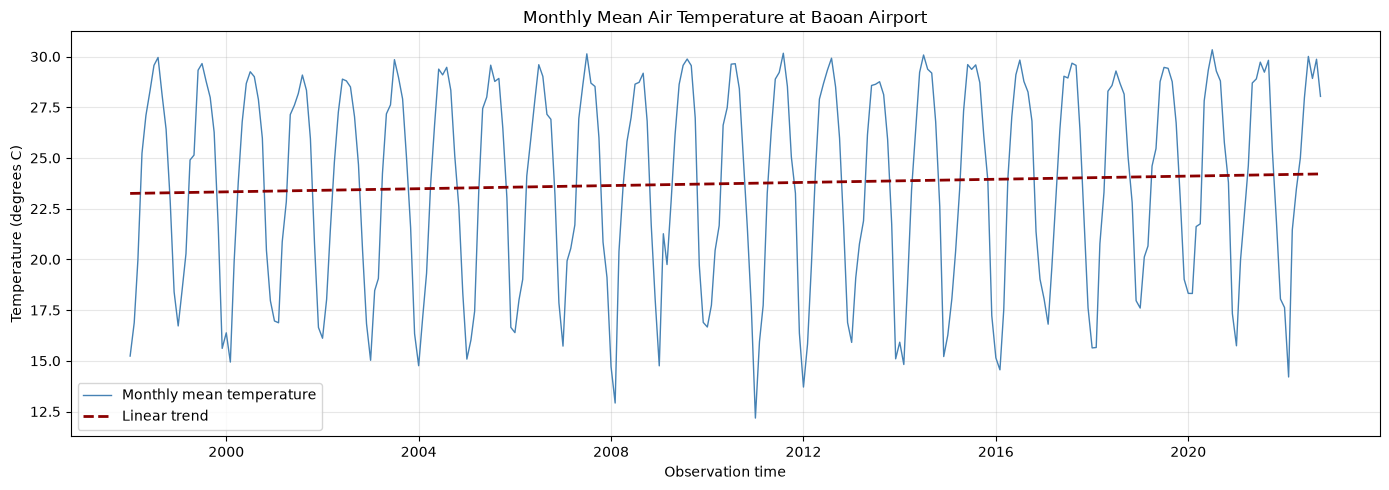

Valid observations: 234864
Monthly points: 298
Temperature range: 1.8 38.0
Linear trend: 0.03881566936867783 degrees C per year
Trend per decade: 0.3881566936867783 degrees C
Correlation: 0.05568031128709581


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CSV_FILE = Path(
    r"C:\Users\admin\Baoan_Weather_1998_2022.csv"
)

PDF_FILE = Path(
    r"C:\Users\admin\isd-format-document.pdf"
)

print("CSV exists:", CSV_FILE.exists())
print("PDF exists:", PDF_FILE.exists())

weather = pd.read_csv(
    CSV_FILE,
    usecols=["DATE", "TMP"],
)

weather["DATE"] = pd.to_datetime(
    weather["DATE"],
    errors="coerce"
)

tmp_parts = weather["TMP"].str.split(
    ",",
    expand=True
)

weather["TEMP_C"] = (
    pd.to_numeric(tmp_parts[0], errors="coerce")
    / 10
)

weather["TMP_QC"] = tmp_parts[1]

bad_qc = ["2", "3", "6", "7"]

valid_rows = (
    weather["DATE"].notna()
    & weather["TEMP_C"].between(-93.2, 61.8)
    & (weather["TMP_QC"].isin(bad_qc) == False)
)

weather = weather.loc[valid_rows].copy()

weather = weather[
    weather["DATE"].dt.year.between(1998, 2022)
].copy()

weather["YEAR_MONTH"] = (
    weather["DATE"].dt.to_period("M")
)

monthly_temperature = (
    weather.groupby("YEAR_MONTH")["TEMP_C"]
    .mean()
)

monthly_temperature.index = (
    monthly_temperature.index.to_timestamp()
)

monthly_temperature = monthly_temperature.dropna()

x = (
    monthly_temperature.index.year
    + (monthly_temperature.index.month - 1) / 12
)

y = monthly_temperature.values

slope_per_year, intercept = np.polyfit(x, y, 1)

trend_line = slope_per_year * x + intercept

correlation = np.corrcoef(x, y)[0, 1]

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_temperature.index,
    monthly_temperature.values,
    color="steelblue",
    linewidth=1,
    label="Monthly mean temperature"
)

plt.plot(
    monthly_temperature.index,
    trend_line,
    color="darkred",
    linewidth=2,
    linestyle="--",
    label="Linear trend"
)

plt.title("Monthly Mean Air Temperature at Baoan Airport")
plt.xlabel("Observation time")
plt.ylabel("Temperature (degrees C)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Valid observations:", len(weather))
print("Monthly points:", len(monthly_temperature))
print("Temperature range:", weather["TEMP_C"].min(), weather["TEMP_C"].max())
print("Linear trend:", slope_per_year, "degrees C per year")
print("Trend per decade:", slope_per_year * 10, "degrees C")
print("Correlation:", correlation)